# Интеллектуальный анализ данных – весна 2026
# Домашнее задание 6: классификация текстов

Правила:



*   Домашнее задание оценивается в 10 баллов.
*   Можно использовать без доказательства любые результаты, встречавшиеся на лекциях или семинарах по курсу, если получение этих результатов не является вопросом задания.
*  Можно использовать любые свободные источники с *обязательным* указанием ссылки на них.
*  Плагиат не допускается. При обнаружении случаев списывания, 0 за работу выставляется всем участникам нарушения, даже если можно установить, кто у кого списал.
*  Старайтесь сделать код как можно более оптимальным. В частности, будет штрафоваться использование циклов в тех случаях, когда операцию можно совершить при помощи инструментов библиотек, о которых рассказывалось в курсе.
* Если в задании есть вопрос на рассуждение, то за отсутствие ответа на него балл за задание будет снижен вполовину.

В этом домашнем задании вам предстоит построить классификатор текстов.

Будем предсказывать эмоциональную окраску твиттов о коронавирусе.



In [83]:
import numpy as np
import pandas as pd
from typing import  List
import matplotlib.pyplot as plt
import seaborn as sns
from string import punctuation

In [84]:
df = pd.read_csv('/content/tweets_coronavirus.csv', encoding='latin-1')
df.sample(4)

,UserName,ScreenName,Location,TweetAt,OriginalTweet,Sentiment
12551,19012,63964,NaN,22-03-2020,AmazonÃÂs Black Market: Reviews https://t.co...,Positive
16373,23737,68689,"Dallas, TX",24-03-2020,Coronavirus market focus: potatoes \r\r\nTryi...,Extremely Negative
26744,36595,81547,An invisible dot,07-04-2020,"https://t.co/os8fxZ4Zpd ""If you think fighting...",Extremely Negative
15892,23123,68075,"Gothenburg, Sweden",24-03-2020,What are 10 emerging cross-industry trends tha...,Extremely Negative


Для каждого твитта указано:


*   UserName - имя пользователя, заменено на целое число для анонимности
*   ScreenName - отображающееся имя пользователя, заменено на целое число для анонимности
*   Location - местоположение
*   TweetAt - дата создания твитта
*   OriginalTweet - текст твитта
*   Sentiment - эмоциональная окраска твитта (целевая переменная)



## Задание 1 Подготовка (0.5 балла)

Целевая переменная находится в колонке `Sentiment`.  Преобразуйте ее таким образом, чтобы она стала бинарной: 1 - если у твитта положительная или очень положительная эмоциональная окраска и 0 - если отрицательная или очень отрицательная.

In [85]:
df['Sentiment'].unique()

array(['Positive', 'Extremely Negative', 'Negative', 'Extremely Positive'],
      dtype=object)

In [86]:
df['Sentiment'] = df['Sentiment'].isin(['Positive', 'Extremely Positive']).astype(int)

Сбалансированы ли классы?

In [87]:
df['Sentiment'].value_counts()

,count
Sentiment,
1,18046
0,15398


**Ответ:** Классы сбалансированы, серьезного перекоса нет, количества объектов в классах примерно одинаковые.

Выведете на экран информацию о пропусках в данных. Если пропуски присутствуют заполните их строкой 'Unknown'.

In [88]:
df.isna().sum()

,0
UserName,0
ScreenName,0
Location,7049
TweetAt,0
OriginalTweet,0
Sentiment,0


In [89]:
df['Location'] = df['Location'].fillna('Unknown')

In [90]:
df.isna().sum()

,0
UserName,0
ScreenName,0
Location,0
TweetAt,0
OriginalTweet,0
Sentiment,0


Разделите данные на обучающие и тестовые в соотношении 7 : 3 и укажите `random_state=0`

In [91]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df, test_size=0.3, random_state=0)

## Задание 2 Токенизация (3 балла)

Постройте словарь на основе обучающей выборки и посчитайте количество встреч каждого токена с использованием самой простой токенизации - деления текстов по пробельным символам и приведения токенов в нижний регистр.

In [92]:
vocab = train['OriginalTweet'].str.lower().str.split().explode()

Какой размер словаря получился?

In [93]:
vocab.value_counts()

,count
OriginalTweet,
the,26815
to,23373
and,14684
of,13012
a,11737
...,...
thc,1
telescope,1
amble,1


In [94]:
len(vocab.value_counts())

79755

Выведите 10 самых популярных токенов с количеством встреч каждого из них. Объясните, почему именно эти токены в топе.

In [95]:
vocab.value_counts().head(10)

,count
OriginalTweet,
the,26815
to,23373
and,14684
of,13012
a,11737
in,11198
for,8566
#coronavirus,8223
is,7383


**Ответ:** В топе оказались частице, предлоги, союзы, т.к. это служебные части речи, которые чаще всего встречаются в любом тексте, мы использовали простую токенизацию, поэтому у нас сохранились стоп-слова. Единственное, слово, которое несет смысловую нагрузку - #coronavirus, так как текст об этом.

Удалите стоп-слова из словаря и выведите новый топ-10 токенов (и количество встреч) по популярности.  Что можно сказать  о нем?

In [96]:
import nltk
from nltk.corpus import stopwords
nltk.download("stopwords", quiet=True)

True

In [97]:
noise = set(stopwords.words("english"))
filter_vocab = vocab[vocab.isin(noise) == False]
filter_vocab.value_counts().head(10)

,count
OriginalTweet,
#coronavirus,8223
prices,3891
food,3820
grocery,3469
supermarket,3288
people,3175
covid-19,3173
store,3155
#covid19,2471


**Ответ:**  После удаления стоп-слов контекст стал более понятным, речь идет о социальных и экономических проблемах в период пандемии. Но в данных остался мусор, который необходимо удалить, например на 10 месте располагется последовательность букв, которая не несет смысловой нагрузки, на 7 и 9 месте одно и тоже слово записанное по-разному. В общем еще нужно чистить

Также выведите 20 самых непопулярных слов (если самых непопулярных слов больше, выведите любые 20 из них) Почему эти токены непопулярны, требуется ли как-то дополнительно работать с ними?

In [98]:
filter_vocab.value_counts().tail(20)

,count
OriginalTweet,
#selfishpoliticians,1
iwe,1
#kifonikifo,1
@fredtjoseph,1
zoolert,1
but!,1
"travel),",1
@naturenews,1
https://t.co/of8j2riotl,1


**Ответ:** Здесь ссылки на сайт, упоминание конкретных юзеров, специфические хештеги, а ткже следствия сырой токенизации: из-зи того, что мы делили слова по пробелам к словам, которые в речи достаточно популярны прицепились пунктуационные знаки, из-за этого при удалении стоп-слов они не исчезли. Так это оставлять явно нельзя, потому что это вызывает шум в данных



Теперь воспользуемся токенайзером получше - TweetTokenizer из библиотеки nltk. Примените его и посмотрите на топ-10 популярных слов. Чем он отличается от топа, который получался раньше? Почему?

In [99]:
from nltk.tokenize import TweetTokenizer

tw = TweetTokenizer()
vocab = []
for tweet in train['OriginalTweet'].str.lower():
  vocab.extend(tw.tokenize(tweet))
vocab = pd.Series(vocab)
vocab.value_counts().head(10)

,count
the,26993
.,24118
to,23478
",",17571
and,14825
of,13044
a,11891
in,11348
?,9524
#coronavirus,8808


**Ответ:** Перестали появляться слова с прилипшими знаками пунктуации, с разделением этот токенайзер лучше справился. TweetTokenizer правильно отделяет знаки препинания, вынося их в отдельный токен, кроме того символы #, @ он относит к слову, зная специфику соцсетей


Удалите из словаря стоп-слова и пунктуацию, посмотрите на новый топ-10 слов с количеством встреч, есть ли теперь в нем что-то не похожее на слова?

In [100]:
from string import punctuation

noise = set(stopwords.words("english"))
noise.update(punctuation)
filter_vocab = vocab[vocab.isin(noise) == False]
filter_vocab.value_counts().head(10)

,count
#coronavirus,8808
â,7415
,7311
19,7167
covid,6253
prices,4601
,4372
food,4367
store,3877
supermarket,3805


**Ответ:** Топ 10 стал гораздо осмысленнее, остались тематические токены, которые передают смысл текста, но сохранились символы в том числе символы Unicode, которые TweetTokenizer не отфильтровал - это и есть мусор

Скорее всего в некоторых топах были неотображаемые символы или отдельные буквы не латинского алфавита. Уберем их: удалите из словаря токены из одного символа, позиция которого в таблице Unicode 128 и более (`ord(x) >= 128`)

Выведите топ-10 самых популярных и топ-20 непопулярных слов. Чем полученные топы отличаются от итоговых топов, полученных при использовании токенизации по пробелам? Что теперь лучше, а что хуже?

In [101]:
vocab = []

for token in filter_vocab:
  if not (len(token) == 1 and ord(token) >= 128):
    vocab.append(token)
vocab = pd.Series(vocab)


In [102]:
vocab.value_counts().head(10)

,count
#coronavirus,8808
19,7167
covid,6253
prices,4601
food,4367
store,3877
supermarket,3805
grocery,3523
people,3463
#covid19,2589


In [103]:
vocab.value_counts().tail(20)

,count
flew,1
@torontopearson,1
@680news,1
https://t.co/1m881cwfuv,1
#unityinourcommunity,1
harlow,1
@halfon4harlowmp,1
#harlow,1
#essex,1
https://t.co/wjasecsbah,1


**Ответ:** В топе слова стали осмысленными, отражающими суть, опираясь на них можно что-то сказать о тексте. Внизу из списка ушли слова с приклеиными знаками препинания, фильтр Unicode убрал нечитаемые смайлики и кодировки. Повысилась точность выделяемого смысла в тексте, исчезли ложно-редкие слова.
Но осталась проблема морфологии, разные формы слова считаются по отдельности

Выведите топ-10 популярных хештегов (токены, первые символы которых - #) с количеством встреч. Что можно сказать о них?

In [104]:
hashtags = []
for token in vocab:
    if token[0] == '#':
        hashtags.append(token)
vocab_hashtags = pd.Series(hashtags).value_counts()

In [105]:
vocab_hashtags.head(10)

,count
#coronavirus,8808
#covid19,2589
#covid_19,1734
#covid2019,946
#toiletpaper,744
#covid,641
#socialdistancing,465
#coronacrisis,448
#pandemic,257
#coronaviruspandemic,249


**Ответ:** Они отражают тему текста, также по ним можно понять подтемы, но все они связаны с проблемами во время пандемии

То же самое проделайте для ссылок на сайт https://t.co Сравнима ли популярность ссылок с популярностью хештегов? Будет ли информация о ссылке на конкретную страницу полезна?

In [106]:
links = []
for token in vocab:
    if 'https://t.co' in token:
        links.append(token)
vocab_links = pd.Series(links).value_counts()

In [107]:
vocab_links.head(10)

,count
https://t.co/oxa7swtond,5
https://t.co/gp3eusapl8,4
https://t.co/kuwipf1kqw,3
https://t.co/oi39zsanq8,3
https://t.co/wuieefsnoj,3
https://t.co/3gbbdpdjat,3
https://t.co/aziqcdgrnn,3
https://t.co/wrlhyzizaa,3
https://t.co/zjnrx6dkkn,3
https://t.co/deftrui1pfãâ,3


**Ответ:** Популярность ссылок гораздо меньше, кроме того по их названию невозможно понять о чем речь в э той ссылке, поэтому по ним не понять о чем говорится в тексте

Используем опыт предыдущих экспериментов и напишем собственный токенайзер, улучшив TweetTokenizer. Функция tokenize должна:



*   Привести текст в нижний регистр
*   Применить TweetTokenizer для  выделения токенов
*   Удалить стоп-слова, пунктуацию, токены из одного символа с позицией в таблице Unicode 128 и более,  ссылки на t.co



In [108]:
def custom_tokenizer(text):
  tokens = tw.tokenize(text.lower())
  tokens = [token for token in tokens if token not in noise]
  tokens = [token for token in tokens if not (len(token) == 1 and ord(token[0]) >= 128)]
  tokens = [token for token in tokens if 'https://t.co' not in token]
  return tokens

In [109]:
custom_tokenizer('This is sample text!!!! @Sample_text I, \x92\x92 https://t.co/sample  #sampletext')

['sample', 'text', '@sample_text', '#sampletext']

## Задание 3 Векторизация текстов (2 балла)

Обучите CountVectorizer с использованием custom_tokenizer в качестве токенайзера. Как размер полученного словаря соотносится с размером изначального словаря из начала задания 2?

In [110]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(tokenizer=custom_tokenizer)
cv.fit(train['OriginalTweet'])
print(len(cv.vocabulary_))

/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


45288


**Ответ:** Текущий словарь гораздо меньше, построенного через split. Сейчас удаляются стоп-слова, пунктуация, ссылки и символы, а также приводятся к нижнему регистру и удаляются дубликаты

Посмотрим на какой-нибудь конкретный твитт:

In [111]:
ind = 9023
train.iloc[ind]['OriginalTweet'], train.iloc[ind]['Sentiment']

('Nice one @SkyNews lets not panic but show ppl in france queueing for food!!! #CoronavirusOutbreak #COVID2019 brainless!! Ffs',
 np.int64(0))

Автор твитта не доволен ситуацией с едой во Франции и текст имеет резко негативную окраску.

Примените обученный CountVectorizer для векторизации данного текста, и попытайтесь определить самый важный токен и самый неважный токен (токен, компонента которого в векторе максимальна/минимальна, без учета 0). Хорошо ли они определились, почему?

In [112]:
text = train.iloc[ind]['OriginalTweet']
vector = cv.transform([text])
df_tweet = pd.DataFrame(vector.toarray(), columns=cv.get_feature_names_out())
act_tokens = df_tweet.loc[:, df_tweet.iloc[0] > 0]
act_tokens

,#coronavirusoutbreak,#covid2019,@skynews,brainless,ffs,food,france,lets,nice,one,panic,ppl,queueing,show
0,1,1,1,1,1,1,1,1,1,1,1,1,1,1


**Ответ:** Самый важный токен тот, у которого наибольший счетчик, то есть наибольшее число повторений. Наименее важный тот, который встретился 1 раз. Но в коротком твите большинство слов встречается 1 раз и понять какое из них важнее невозможно. CountVectorizer учитывает частоту слова только в 1 твите, но он не может оценить смысловую значимость.

Теперь примените TfidfVectorizer и  определите самый важный/неважный токены. Хорошо ли определились, почему?

In [113]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(tokenizer=custom_tokenizer)
tfidf.fit(train['OriginalTweet'])
tfidf_vec = tfidf.transform([text])
df_tweet = pd.DataFrame(tfidf_vec.toarray(), columns=tfidf.get_feature_names_out())
act_tokens = df_tweet.loc[:, df_tweet.iloc[0] > 0]

/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


In [114]:
act_tokens

,#coronavirusoutbreak,#covid2019,@skynews,brainless,ffs,food,france,lets,nice,one,panic,ppl,queueing,show
0,0.225843,0.168252,0.310426,0.386764,0.324474,0.113289,0.320473,0.301211,0.254273,0.163067,0.147595,0.255006,0.354346,0.244065


**Ответ:** Твит короткий, из-за этого каждое слово встречается 1 раз, поэтому TF одинаков для всех токенов, и получается, что все цифры получились только за счет IDF. То есть наибольший вес получают слова, которые просто редкие по всем твитам. Самый важен токен по TF-IDF может быть просто редким словом, но не имеющим смыслового веса

Найдите какой-нибудь положительно окрашенный твитт, где TfidfVectorizer хорошо (полезно для определения окраски) выделяет важный токен, поясните пример.

*Подсказка:* явно положительные твитты можно искать при помощи положительных слов (good, great, amazing и т. д.)

In [115]:
train[train['OriginalTweet'].apply(lambda x: 'your_good_word_here' in x) & (train['Sentiment'] == 1)]

,UserName,ScreenName,Location,TweetAt,OriginalTweet,Sentiment


In [116]:
filter = train[train['OriginalTweet'].apply(lambda x: 'good' in x.lower()) & (train['Sentiment'] == 1)]
ind_filt = filter.index[0]
filt_text = train.loc[ind_filt, 'OriginalTweet']

In [117]:
tdif_vec = tfidf.transform([filt_text])
df_tweet = pd.DataFrame(tdif_vec.toarray(), columns=tfidf.get_feature_names_out())
filt_tokens = df_tweet.loc[:, df_tweet.iloc[0] > 0]
filt_tokens

,#coronavirus,#marketingstrategy,@mckinsey,article,change,crisis,customer,friends,good,marketers,marketing,ready,regarding,sentiment,strategy,whole
0,0.076699,0.374217,0.304912,0.237534,0.222324,0.158981,0.235606,0.229644,0.179075,0.310077,0.256918,0.24139,0.253786,0.261358,0.283266,0.237253


**Ответ:** Определились лучше,с высоким весом слова, которые редкие по всем твитам в целом, но значимые в данном твите. Но среди токенов с высоким весом есть и те которые в данном случае не несут в себе смысловых разъяснений. Полностью определить эмоциональную окраску твита через TF - IDF по 1 твиту невозможно

## Задание 4 Обучение первых моделей (1 балл)

Примените оба векторайзера для получения матриц с признаками текстов.  Выделите целевую переменную.

In [118]:
y_test = test['Sentiment']
y_train = train['Sentiment']

x_cv_tr = cv.fit_transform(train['OriginalTweet'])
x_cv_t = cv.transform(test['OriginalTweet'])

x_tfidf_tr = tfidf.fit_transform(train['OriginalTweet'])
x_tfidf_t = tfidf.transform(test['OriginalTweet'])

/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


Обучите логистическую регрессию на векторах из обоих векторайзеров. Посчитайте долю правильных ответов на обучающих и тестовых данных. Какой векторайзер показал лучший результат? Что можно сказать о моделях?

Используйте `sparse` матрицы (после векторизации), не превращайте их в `numpy.ndarray` или `pd.DataFrame` - может не хватить памяти.

In [119]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr = LogisticRegression()
lr.fit(x_cv_tr, y_train)
print(accuracy_score(y_train, lr.predict(x_cv_tr)))
print(accuracy_score(y_test, lr.predict(x_cv_t)))

0.9847073900042717
0.8673510065776361


In [120]:
lr.fit(x_tfidf_tr, y_train)
print(accuracy_score(y_train, lr.predict(x_tfidf_tr)))
print(accuracy_score(y_test, lr.predict(x_tfidf_t)))

0.9224263135412217
0.8527008172214471


**Ответ:** Оба векторайзера показывают хорошие результаты, но в нашем случае СountVectorizer показывает результат немного лучше, хотя TF-IDF получше, так как учитывает не только частоту токенов в документе, но и его редкость по всем документам. В обоих случаях тренировочная выборка лучше тестовой, но это можно объяснить тем, что словарь большой и признаков в нем много

## Задание 5 Стемминг (0.5 балла)

Для уменьшения словаря можно использовать стемминг.

Модифицируйте написанный токенайзер, добавив в него стемминг с использованием SnowballStemmer. Обучите Count- и Tfidf- векторайзеры. Как изменился размер словаря?

In [121]:
from nltk.stem import SnowballStemmer
stemmer = SnowballStemmer('english')

In [122]:
def custom_stem_tokenizer(text):
  tokens = custom_tokenizer(text)
  tokens = [stemmer.stem(token) for token in tokens]
  return tokens

In [123]:
custom_stem_tokenizer('This is sample text!!!! @Sample_text I, \x92\x92 https://t.co/sample  #sampletext adding more words to check stemming')

['sampl', 'text', '@sample_text', '#sampletext', 'ad', 'word', 'check', 'stem']

In [124]:
cv = CountVectorizer(tokenizer=custom_stem_tokenizer)
cv.fit(train['OriginalTweet'])
print(len(cv.vocabulary_))

/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


36632


In [125]:
tfidf = TfidfVectorizer(tokenizer=custom_stem_tokenizer)
tfidf.fit(train['OriginalTweet'])
print(len(tfidf.vocabulary_))

36632


**Ответ** После стемминга размер значительно уменьшился, так как морфологически разные слова сводятся к одной основе. Это снижает размерность и уменьшает переобучение.

Обучите логистическую регрессию с использованием обоих векторайзеров. Изменилось ли качество? Есть ли смысл применять стемминг?

In [126]:
x_cv_stem_tr = cv.transform(train['OriginalTweet'])
x_cv_stem_t = cv.transform(test['OriginalTweet'])
x_tfidf_stem_tr = tfidf.transform(train['OriginalTweet'])
x_tfidf_stem_t = tfidf.transform(test['OriginalTweet'])

lr.fit(x_cv_stem_tr, y_train)
print('cv_stem_train:', accuracy_score(y_train, lr.predict(x_cv_stem_tr)))
print('cv_stem_test:', accuracy_score(y_test, lr.predict(x_cv_stem_t)))

lr.fit(x_tfidf_stem_tr, y_train)
print('tfidf_stem_train:', accuracy_score(y_train, lr.predict(x_tfidf_stem_tr)))
print('tfidf_stem_test:', accuracy_score(y_test, lr.predict(x_tfidf_stem_t)))

cv_stem_train: 0.9720632208457924
cv_stem_test: 0.8671516842734702
tfidf_stem_train: 0.9161469457496796
tfidf_stem_test: 0.8562886186964321


**Ответ:** Качество на тестах изменилось незначительно. Стемминг уменьшил размер словаря и чуть-чуть снизил переобучение, но при этом произошла потеря информации, так как приведение к единой основе сводит слова с разным значением к 1 слову. В данном случае использование стемминга не обосновано.

## Задание  6 Работа с частотами (1.5 балла)

Еще один способ уменьшить количество признаков - это использовать параметры min_df и max_df при построении векторайзера  эти параметры помогают ограничить требуемую частоту встречаемости токена в документах.

По умолчанию берутся все токены, которые встретились хотя бы один раз.



Подберите max_df такой, что размер словаря будет 36651 (на 1 меньше, чем было). Почему параметр получился такой большой/маленький?

In [127]:
cv_full = cv.fit(train['OriginalTweet'])
size0 = len(cv_full.vocabulary_)
print('Изначальный размер:', size0)

x_full = cv_full.transform(train['OriginalTweet'])
n_doc = x_full.shape[0]
doc1 = np.asarray(x_full.sum(axis=0)).ravel()
max_count = doc1.max()
max_df_val = int(max_count) - 1
print('max_df:', max_df_val)

/usr/local/lib/python3.12/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


Изначальный размер: 36632
max_df: 8808


In [128]:
cv_df = CountVectorizer(tokenizer=custom_stem_tokenizer,
                        max_df=max_df_val
                        ).fit(train['OriginalTweet'])

print(len(cv_df.vocabulary_))

36632


**Ответ:** Параметр очень большой, так как даже самы частый токен встречается не в том количестве твитов, которое необхождимо. Твиты короткие и разнообразные, поэтому ни один токен не доминирует

Подберите min_df (используйте дефолтное значение max_df) в CountVectorizer таким образом, чтобы размер словаря был 3700 токенов (при использовании токенайзера со стеммингом), а качество осталось таким же, как и было. Что можно сказать о результатах?

In [129]:
for min_df_val in [5, 8, 10, 11, 12]:
  cv_test = CountVectorizer(tokenizer=custom_stem_tokenizer, min_df=min_df_val).fit(train['OriginalTweet'])
  if len(cv_test.vocabulary_) <= 3700:
    print('min_df:', min_df_val, 'vocab size:', len(cv_test.vocabulary_))

min_df: 11 vocab size: 3687
min_df: 12 vocab size: 3476


In [130]:
x_cv_df_tr = cv_df.transform(train['OriginalTweet'])
x_cv_df_t = cv_df.transform(test['OriginalTweet'])
lr = LogisticRegression()
lr.fit(x_cv_df_tr, y_train)
print('cv_df_train:', accuracy_score(y_train, lr.predict(x_cv_df_tr)))
print('cv_df_test:', accuracy_score(y_test, lr.predict(x_cv_df_t)))

cv_df_train: 0.9720632208457924
cv_df_test: 0.8671516842734702


**Ответ:** Словарь уменьшился почти в 10 раз, но при этом качество на тестах практически не изменилось. Благодаря тому, что редкие токены несут мало смысловой информации и больше вносят шум. Сокращение словаря ускоряет обучение и уменьшает используемую память

В предыдущих заданиях признаки не скалировались. Отскалируйте данные (при словаре размера 3.7 тысяч, векторизованные CountVectorizer), обучите логистическую регрессию, посмотрите качество и выведите `barplot`, содержащий по 10 токенов, с наибольшим по модулю положительными/отрицательными весами. Что можно сказать об этих токенах?

In [131]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler(with_mean=False)
x_cv_df_tr = scaler.fit_transform(x_cv_df_tr)
x_cv_df_t = scaler.transform(x_cv_df_t)
lr.fit(x_cv_df_tr, y_train)
print('Train:', accuracy_score(y_train, lr.predict(x_cv_df_tr)))
print('Test:', accuracy_score(y_test, lr.predict(x_cv_df_t)))

Train: 0.9999572832123025
Test: 0.781044448873829


<BarContainer object of 20 artists>

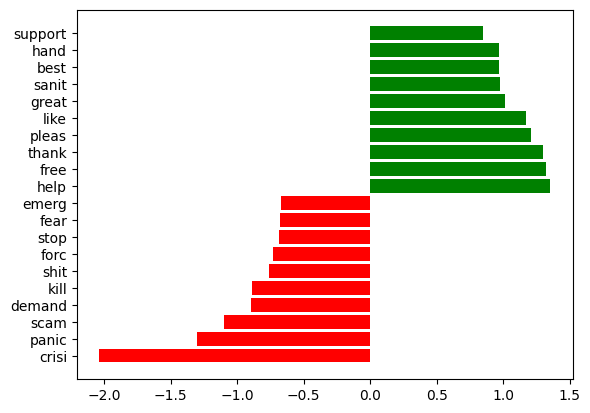

In [132]:
coefs = pd.Series(lr.coef_[0], index=cv_df.get_feature_names_out())
top = pd.concat([coefs.nsmallest(10), coefs.nlargest(10)])
colors = ['red' if c < 0 else 'green' for c in top]
plt.barh(top.index, top.values, color=colors)

При построении графика использовались методы nsmallest(), nlargest(), использовался сайт https://docs-python.ru/packages/modul-pandas-analiz-dannykh-python/metody-nsmallest-nlargest/

**Ответ:** Зеленые токены - это основы слов с положительным окрасом, красные - токены с негативным окрасом. Модель корректно выделила смысл слов, а масштабирование показало вклад редких, но информативных слов

## Задание 7 Другие признаки (1.5 балла)

Мы были сконцентрированы на работе с текстами твиттов и не использовали другие признаки - имена пользователя, дату и местоположение

Изучите признаки UserName и ScreenName. полезны ли они? Если полезны, то закодируйте их, добавьте к матрице с отскалированными признаками, обучите логистическую регрессию, замерьте качество.

In [133]:
print('UserName уникальные значения:', train['UserName'].nunique())
print('ScreenName уникальные значения:', train['ScreenName'].nunique())
print(train[['UserName', 'ScreenName']].head(5))

UserName уникальные значения: 23410
ScreenName уникальные значения: 23410
       UserName  ScreenName
25621     35178       80130
30135     40819       85771
28899     39249       84201
5989      11068       56020
4367       9109       54061


**Ответ:**  UserName, ScreenName не несут смысловой нагрузки, они никак не связаны с тональностью твита. Нет смысла их добавлять в матрицу признаков, модель запомнит случайные закономерности, например, пользователь писал чаще положительные твиты. Это переобучение, поэтому эти признаки добавлять не стоит



Изучите признак TweetAt в обучающей выборке: преобразуйте его к типу datetime и нарисуйте его гистограмму с разделением по цвету на основе целевой переменной. Полезен ли он? Если полезен, то закодируйте его, добавьте к матрице с отскалированными признаками, обучите логистическую регрессию, замерьте качество.

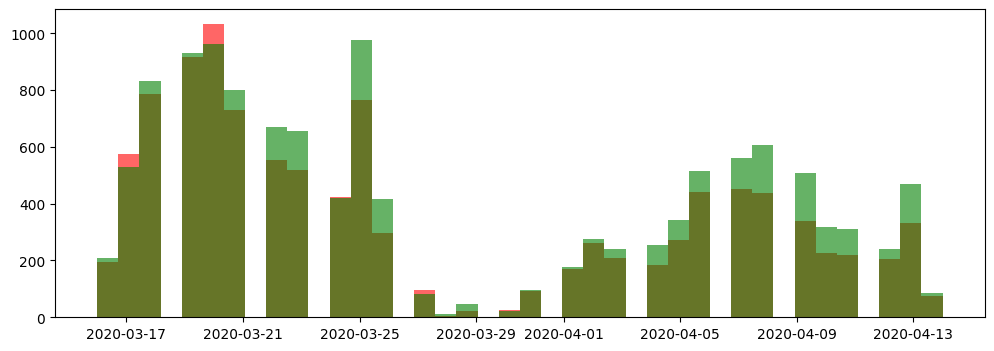

In [134]:
train['TweetAt'] = pd.to_datetime(train['TweetAt'], dayfirst=True)
test['TweetAt'] = pd.to_datetime(test['TweetAt'], dayfirst=True)

fig, ax = plt.subplots(figsize=(12, 4))
plt.hist(train[train['Sentiment'] == 0]['TweetAt'], bins=40, alpha=0.6, color='red')
plt.hist(train[train['Sentiment'] == 1]['TweetAt'], bins=40, alpha=0.6, color='green')
plt.show()

In [135]:
train_date = train['TweetAt'].astype(np.int64).values.reshape(-1, 1)
test_date = test['TweetAt'].astype(np.int64).values.reshape(-1, 1)
train_date = scaler.fit_transform(train_date)
test_date = scaler.transform(test_date)
x_train_date = np.hstack([x_cv_df_tr.toarray(), train_date])
x_test_date = np.hstack([x_cv_df_t.toarray(), test_date])
lr = LogisticRegression(max_iter=500, random_state = 67)
lr.fit(x_train_date, y_train)
print(accuracy_score(y_train, lr.predict(x_train_date)))
print(accuracy_score(y_test, lr.predict(x_test_date)))

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.999700982486117
0.7790512258321706


**Ответ:** Гистограмма показывает, что распределение позитивных и негативных твитов по времени примерно одинаковое. Добавление даты почти не влияет на качество классификации. TweetAt не полезен для данной задачи




Поработайте с признаком Location в обучающей выборке. Сколько уникальных значений?

In [136]:
print('Уникальных значений Location:', train['Location'].nunique())
train['Location'].value_counts().head(10)

Уникальных значений Location: 7949


,count
Location,
Unknown,4944
London,301
United States,295
"London, England",274
"New York, NY",223
"Washington, DC",222
United Kingdom,204
"Los Angeles, CA",154
India,153


Постройте гистограмму топ-10 по популярности местоположений (исключая Unknown)

<Axes: ylabel='Location'>

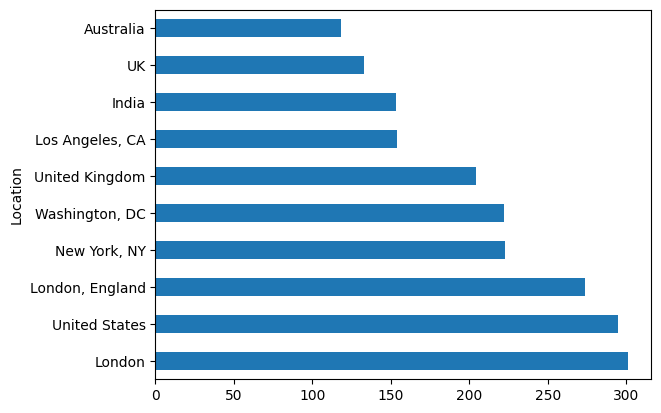

In [137]:
top = train[train['Location'] != 'Unknown']['Location'].value_counts().head(10)
top.plot(kind='barh')

Видно, что многие местоположения включают в себя более точное название места, чем другие (Например, у некоторых стоит London, UK; а у некоторых просто UK или United Kingdom).

Создайте новый признак WiderLocation, который содержит самое широкое местоположение (например, из London, UK должно получиться UK). Сколько уникальных категорий теперь? Постройте аналогичную гистограмму.

In [138]:
# -- YOUR CODE HERE --

Закодируйте признак WiderLocation с помощью OHE таким образом, чтобы создались только столбцы для местоположений, которые встречаются более одного раза. Сколько таких значений?


In [139]:
# -- YOUR CODE HERE --

Добавьте этот признак к матрице отскалированных текстовых признаков, обучите логистическую регрессию, замерьте качество. Как оно изменилось? Оказался ли признак полезным?


*Подсказка:* используйте параметр `categories` в энкодере.

In [140]:
# -- YOUR CODE HERE --

**Ответ:** # -- YOUR ANSWER HERE --